In [1]:
import numpy as np
import pickle
import matplotlib.pyplot as plt
import pandas as pd
import os
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

from _utils._utils_spline import eval_spline_basis_equispaced_numeric
# from _run._run_generate_distortion_data import max_ratio_cd, max_ratio_cond, plot_max_ratio_cond, plot_max_ratio_cond_implementation
# from _run._run_generate_distortion_data_01_bi import max_ratio_cd, max_ratio_cond, plot_max_ratio_cond, plot_max_ratio_cond_implementation
from _run._run_generate_distortion_data_01_mult import max_ratio_cd, max_ratio_cond, plot_max_ratio_cond, plot_max_ratio_cond_implementation

['exponential', 'exponential']
(100, 100, 2)
10
(100, 1, 2) (100, 1, 2)
20
(100, 1, 2) (100, 1, 2)
50
(100, 1, 2) (100, 1, 2)
100
(100, 1, 2) (100, 1, 2)
['exponential', 'exponential'] 10
0
20
40
60
80
['exponential', 'exponential'] 20
0
20
40
60
80
['exponential', 'exponential'] 50
0
20
40
60
80
['exponential', 'exponential'] 100
0
20
40
60
80
['exponential', 'exponential'] 10
0
20
40
60
80
['exponential', 'exponential'] 20
0
20
40
60
80
['exponential', 'exponential'] 50
0
20
40
60
80
['exponential', 'exponential'] 100
0
20
40
60
80


In [2]:
def I(n):
    return np.eye(n)
def e(n, j):
    e = np.zeros((n, 1))
    e[j-1] = 1
    return e
def R(n, j):
    return I(n) - np.ones((n, 1)) @ e(n, j).T
def Q(B):
    n, k = B.shape
    return I(k) - np.ones((k, 1)) @ (np.ones((n,1)).T @ B)/n

###

def max_ratio_cd(k):
    v = (np.ones((k, 1)).T @  R(k, k)).T
    return v / np.linalg.norm(v, 2)

def max_ratio_cond(B):
    k = B.shape[1]
    v = (np.ones((k, 1)).T @  Q(B)).T
    return v / np.linalg.norm(v, 2), np.linalg.norm(v, 2)

In [3]:
def generate_data_dict(distribution_list_list, n_list, replication_list, x_range=[0.0, 1.0], seed=0):
    data_dict = {}
    for dist_list in distribution_list_list:
        print(dist_list)
        np.random.seed(seed)

        n_max = max(n_list)
        x = [None for dist in dist_list]
        for i, dist in enumerate(dist_list):
            if dist == 'uniform':
                x[i] = np.random.uniform(x_range[0], x_range[1], (len(replication_list), n_max))
            elif dist == 'uni_normal':
                x[i] = np.random.normal(0.0, 1.0, (len(replication_list), n_max))
            elif dist == 'bi_normal':
                # more distant modes
                # x = np.concatenate([np.random.normal(-2.0, 0.5, (len(replication_list), n_max//2)), np.random.normal(0.5, 0.5, (len(replication_list), n_max//2))], axis=1)
                bimode = np.array([8.0, 12.0, 16.0])
                second_mode = np.tile(bimode, len(replication_list)//len(bimode) + 1)[:len(replication_list)]
                rows = []
                for r in replication_list:
                    x_r = np.shuffle(np.concatenate([np.random.normal(0.0, 1.0, n_max//2), np.random.normal(second_mode[r], 1.0, n_max//2)], axis=0))
                    rows.append(x_r)
                x[i] = np.array(rows)
            elif dist == 'exponential':
                x[i] = np.random.exponential(1, (len(replication_list), n_max))
        x = np.stack(x, axis=-1)
        print(x.shape)

        for n_val in n_list:
            print(n_val)
            # x_n = x[:, :n_val] 01
            # 01_alt
            perm = np.random.permutation(x.shape[1])
            x_shuffle = x[:, perm, :]
            x_n = x_shuffle[:, :n_val, :]

            x_n_min = np.min(x_n, axis=1)[:, np.newaxis, :]
            x_n_max = np.max(x_n, axis=1)[:, np.newaxis, :]
            print(x_n_min.shape, x_n_max.shape)
            x_n = (x_n - x_n_min) / (x_n_max - x_n_min) * (x_range[1] - x_range[0]) + x_range[0]
            # x_n.sort(axis=1)

            for i, r in enumerate(replication_list):
                x_n_r = x_n[i].copy()
                #x_n_r = np.concatenate([[x_range[0]], x_n_r, [x_range[1]]])
                #x_n_r.sort()
                data_dict[(tuple(dist_list), n_val, r)] = x_n_r
    return data_dict


In [4]:
distribution_list_list = [['exponential'], ['exponential', 'exponential'], ['exponential', 'exponential', 'exponential']]
n_list = [50]
replication_list = list(range(10))
data_dict = generate_data_dict(distribution_list_list, n_list, replication_list, x_range=[0.0, 1.0], seed=0)

['exponential']
(10, 50, 1)
50
(10, 1, 1) (10, 1, 1)
['exponential', 'exponential']
(10, 50, 2)
50
(10, 1, 2) (10, 1, 2)
['exponential', 'exponential', 'exponential']
(10, 50, 3)
50
(10, 1, 3) (10, 1, 3)


In [5]:
list(data_dict.keys())[::5]

[(('exponential',), 50, 0),
 (('exponential',), 50, 5),
 (('exponential', 'exponential'), 50, 0),
 (('exponential', 'exponential'), 50, 5),
 (('exponential', 'exponential', 'exponential'), 50, 0),
 (('exponential', 'exponential', 'exponential'), 50, 5)]

In [6]:
n = n_list[0]
x = data_dict[(('exponential', 'exponential', 'exponential'), n, 0)]

In [7]:
x.shape

(50, 3)

In [8]:
def generate_curve_dict(distribution_list_list, n_list, replication_list, num_knots, data_dict, plot=False):
    degree = 3
    curve_dict = {}
    pen_dict = {}
    curve_plot_dict = {}

    for dist_list in distribution_list_list:
        for n_val in n_list:
            print(dist_list, n_val)
            for r in replication_list:
                if r % 20 == 0:
                    print(r)
                x_vals = data_dict[(tuple(dist_list), n_val, r)].copy()
                
                if x_vals.shape[0]>num_knots:
                    curve_col = []
                    pen_col = []
                    curve_plot_col = []

                    for col in range(x_vals.shape[1]):
                        x_col = x_vals[:, col]

                        B = eval_spline_basis_equispaced_numeric(degree, np.min(x_col), np.max(x_col), num_knots, x_col)['B']
                        v, pen = max_ratio_cond(B)
                        curve = B@v
                        if plot:
                            x_plot = np.linspace(np.min(x_col), np.max(x_col), 100)
                            B_plot = eval_spline_basis_equispaced_numeric(degree, np.min(x_plot), np.max(x_plot), num_knots, x_plot)['B']
                            curve_plot = B_plot@v
                            curve_plot = (curve_plot - np.min(curve))/(np.max(curve) - np.min(curve))
                            curve_plot_col.append(curve_plot.flatten())
                            # curve_plot_dict[(tuple(dist_list), n_val, r)] = curve_plot
                        curve = (curve - np.min(curve))/(np.max(curve) - np.min(curve))
                        curve_col.append(curve.flatten())
                        pen_col.append(pen.flatten())
                        # curve_dict[(tuple(dist_list), n_val, r)] = curve
                        # pen_dict[(tuple(dist_list), n_val, r)] = pen
                    if plot:
                        curve_plot_dict[(tuple(dist_list), n_val, r)] = np.stack(curve_plot_col, axis=-1)
                    curve_dict[(tuple(dist_list), n_val, r)] = np.stack(curve_col, axis=-1)
                    pen_dict[(tuple(dist_list), n_val, r)] = np.stack(pen_col, axis=-1)
    if plot:           
        return curve_dict, curve_plot_dict, pen_dict
    else:
        return curve_dict, pen_dict
 

In [9]:
num_knots = 5
curve_dict, curve_plot_dict, pen_dict = generate_curve_dict(distribution_list_list, n_list, replication_list, num_knots, data_dict, plot=True)

['exponential'] 50
0
['exponential', 'exponential'] 50
0
['exponential', 'exponential', 'exponential'] 50
0


In [10]:
list(curve_dict.keys())[::5]

[(('exponential',), 50, 0),
 (('exponential',), 50, 5),
 (('exponential', 'exponential'), 50, 0),
 (('exponential', 'exponential'), 50, 5),
 (('exponential', 'exponential', 'exponential'), 50, 0),
 (('exponential', 'exponential', 'exponential'), 50, 5)]

In [11]:
r = 7
x, y, y_plot = data_dict[(('exponential', 'exponential'), n, r)], curve_dict[(('exponential', 'exponential'), n, r)], curve_plot_dict[(('exponential', 'exponential'), n, r)]
x_plot = np.linspace(np.min(x, axis=0), np.max(x, axis=0), 100)


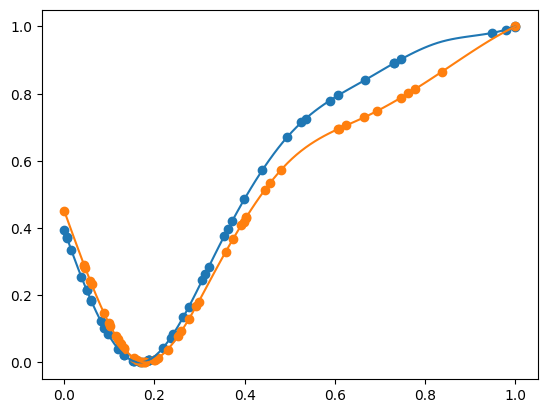

In [12]:
plt.plot(x_plot, y_plot)
for i in range(x.shape[1]):
    plt.scatter(x[:, i], y[:, i], label=f'Column {i+1}')

In [13]:
def generate_data(scale_list, distribution_list_list, n_list, sigma_list, replication_list, num_knots, data_dict, curve_dict):
    f_sigma_list = []
    for dist_list in distribution_list_list:
        for n_val in n_list: 
            for scale in scale_list:
                for sigma in sigma_list:  
                    f_sigma_list.append((f'{str(tuple(dist_list))}_{num_knots}_{n_val}_{scale}', sigma))
    data = {(f, sigma): {} for f, sigma in f_sigma_list}


    np.random.seed(0)
    eps = np.random.normal(0.0, 1.0, (len(replication_list), np.max(n_list)))
    
    for dist_list in distribution_list_list:
        for n_val in n_list:
            print(dist_list, n_val)
            for i, r in enumerate(replication_list):
                if r % 20 == 0:
                    print(r)
                eps_n_r = eps[i, :n_val].copy()
                x_n_r = data_dict[(tuple(dist_list), n_val, r)].copy()
                
                curve = curve_dict[(tuple(dist_list), n_val, r)].copy()
                # curve = curve.flatten()
                
                for scale in scale_list:
                    for sigma in sigma_list:
                        # print(curve.shape, eps_n_r.shape, x_n_r.shape)
                        y = (np.sum(curve, axis=1) + sigma * eps_n_r/5.0) * scale
                        data[(f'{str(tuple(dist_list))}_{num_knots}_{n_val}_{scale}', sigma)][r] = (x_n_r, y)
    return data


In [14]:
sigma_list = [0.05, 0.1, 0.5, 1.0, 5.0]
scale_list = [1]
data = generate_data(scale_list, distribution_list_list, n_list, sigma_list, replication_list, num_knots, data_dict, curve_dict)

['exponential'] 50
0
['exponential', 'exponential'] 50
0
['exponential', 'exponential', 'exponential'] 50
0


In [15]:
data.keys()

dict_keys([("('exponential',)_5_50_1", 0.05), ("('exponential',)_5_50_1", 0.1), ("('exponential',)_5_50_1", 0.5), ("('exponential',)_5_50_1", 1.0), ("('exponential',)_5_50_1", 5.0), ("('exponential', 'exponential')_5_50_1", 0.05), ("('exponential', 'exponential')_5_50_1", 0.1), ("('exponential', 'exponential')_5_50_1", 0.5), ("('exponential', 'exponential')_5_50_1", 1.0), ("('exponential', 'exponential')_5_50_1", 5.0), ("('exponential', 'exponential', 'exponential')_5_50_1", 0.05), ("('exponential', 'exponential', 'exponential')_5_50_1", 0.1), ("('exponential', 'exponential', 'exponential')_5_50_1", 0.5), ("('exponential', 'exponential', 'exponential')_5_50_1", 1.0), ("('exponential', 'exponential', 'exponential')_5_50_1", 5.0)])

In [16]:
r = 3
n = 50
s = sigma_list[2]
x_data, y_data = data[("('exponential', 'exponential')_5_50_1", s)][r]
x = data_dict[(('exponential', 'exponential'), n, r)]
y = curve_dict[(('exponential', 'exponential'), n, r)]
x_plot = np.linspace(np.min(x, axis=0), np.max(x, axis=0), 100)
y_plot = curve_plot_dict[(('exponential', 'exponential'), n, r)]

In [20]:
x_data.shape, y_data.shape

((50, 2), (50,))

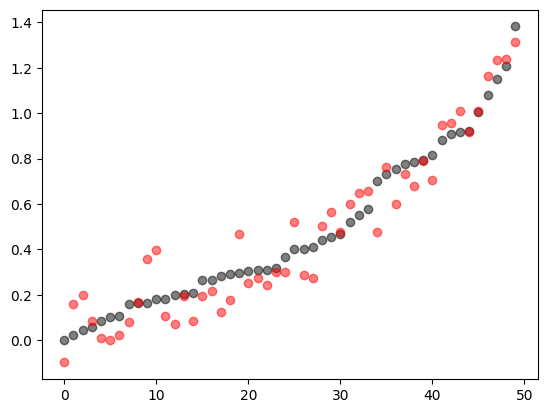

In [17]:
# plt.plot(x_plot, y_plot)
# for i in range(x.shape[1]):
    # plt.scatter(x[:, i], y[:, i], label=f'Column {i+1}')
sum_y = np.sum(y, axis=1)
order = np.argsort(sum_y)
plt.scatter(np.arange(len(y[:, 0])), sum_y[order], label='Sum of curves', color='black', alpha=0.5)
plt.scatter(np.arange(len(y_data)), y_data[order], label='Sum of curves (data)', color='red', alpha=0.5)
# for i in range(x_data.shape[1]):
    # plt.scatter(x_data[:, i], y_data[:], label=f'Column {i+1} (data)', alpha=0.5)